# Caribu, 6: with other models

**What you will learn:** light plants described by another model, here a wheat stand grown by Adel, as Caribu is
meant to be used: an environment model of a metafspm scene.

**You need:** tutorial 1 (its last section). This tutorial needs the package `openalea.adel` (Adel's port to
metafspm) installed. **Run time:** about 30 seconds.

## 1. A growing wheat stand

**Adel** describes the shape of wheat plants as they grow: their leaves, sheaths and stems, each made of small
elements. The example `example/canopy_light.py` (two folders up) builds a stand:

- 20 wheat plants in 4 rows 15 cm apart, sown on 6 May at Paris;
- each plant model is Adel's (`ScenarioShoot`), with its elements' optics (Caribu's `PlantOptics`: how much light
  a leaf or a stem reflects and lets through); the scene adds Caribu's light (`CaribuLightModel`) as its environment
  model;
- each scene step is one hour, and 10 degree-days of plant development;
- the canopy is lit every 4 hours with the sun and the sky, and the PAR above it is that of a clear May day.

Every hour, the light model lights the elements that exist at that moment: as the plants grow, there are more of
them, and they shade each other more.

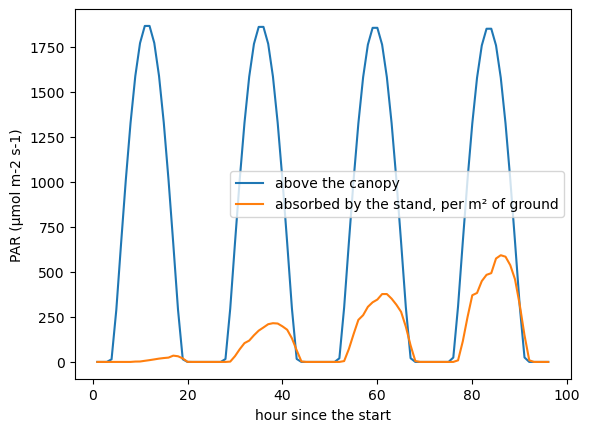

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "../..")                          # example/canopy_light.py
from canopy_light import XRANGE, YRANGE, stand_scene

scene = stand_scene()
light = scene.environment[0].light
lit = light.data_structure                           # the light model's: the stand's elements, as it lit them
hours, incident, absorbed, n_triangles = [], [], [], []
for step in range(96):
    scene.run()
    hours.append(scene.time / 3600.)
    incident.append(light.forcing("PARi"))
    absorbed.append(float(np.sum(np.asarray(lit.get("PARa")) * np.asarray(lit.get("lit_area")))) / (XRANGE * YRANGE))
    n_triangles.append(len(lit.triangles()))
plt.plot(hours, incident, label="above the canopy")
plt.plot(hours, absorbed, label="absorbed by the stand, per m² of ground")
plt.xlabel("hour since the start"); plt.ylabel("PAR (µmol m-2 s-1)"); plt.legend();

Over four days, the stand absorbs a growing share of the light, as its leaves grow:

In [2]:
for day in range(4):
    day_hours = slice(24 * day, 24 * (day + 1))
    share = np.sum(absorbed[day_hours]) / np.sum(incident[day_hours])
    print(f"day {day + 1}: {share:.1%} of the PAR absorbed, {n_triangles[24 * day + 23]} triangles at its end")

day 1: 1.1% of the PAR absorbed, 1044 triangles at its end
day 2: 12.0% of the PAR absorbed, 5206 triangles at its end
day 3: 21.7% of the PAR absorbed, 11474 triangles at its end
day 4: 33.9% of the PAR absorbed, 18454 triangles at its end


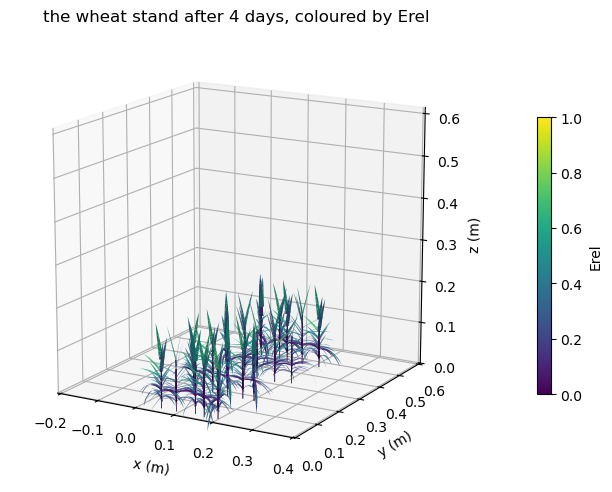

In [3]:
from openalea.metafspm.display import draw, value_colors

figure = plt.figure(figsize=(8, 6))
axes = figure.add_subplot(projection="3d")
lit.update_topology()                                # the elements grown since the last lighting (not lit yet)
draw(axes, lit.triangles(), colors=value_colors(np.asarray(lit.get("Erel")), limits=(0., 1.)))
figure.colorbar(plt.cm.ScalarMappable(cmap="viridis"), ax=axes, shrink=0.6, pad=0.12, label="Erel")
axes.set_title("the wheat stand after 4 days, coloured by Erel");

## 2. What changed compared with `simulate`

The light model is the same `CaribuLight`; only the plants differ. Here they are Adel's: they grow, so the canopy
changes at every step, and the light model lights its new elements. The light's results stay the light model's
(`light.data_structure`); a model of the plants that needs one declares it as an input of the same name, and the
scene links it to the light's: a photosynthesis model in the same plant model could read each element's absorbed
PAR (`PARa`) and make the plants grow from it. That is what coupling models in metafspm means.

Writing such a scene yourself is the subject of the developer tutorials: `../developer/01_caribu_in_metafspm.ipynb`
builds this stand and explains each part.

## Try it yourself

1. Change the lighting interval to 1 hour (in `canopy_light.py`'s `stand_scene`, the light model's `interval`)
   and compare the absorbed PAR: is lighting every 4 hours a good approximation?
2. Run 8 days instead of 4. When does the stand absorb half of the light?